# 08 · Logistic Regression: tune, evaluate, save

Final-model notebook for **Team Plug Detectives (EC5203)**. One of eight model notebooks (05–12), compared side by side under the same rules in **13_model_comparison**.
All eight use the **same data, the same 20 features (chosen in 04 step 4) and the same house-grouped CV**, so their scores are directly comparable.

**Logistic Regression** = a linear model. For each appliance it learns one weight per feature and adds them up into a score; softmax turns the 11 scores into probabilities. Simple, fast and easy to explain, but it can only draw straight (linear) boundaries between classes.

| Step | What it does |
|---|---|
| 1 | Load features, split into 46 dev homes / 10 locked test homes |
| 2 | Score the default model, then grid-search the settings (groups passed, so no home is in train and validation) |
| 3 | Robustness: re-score default vs tuned on 5 new house splits; keep the tuned one only if it wins by more than one standard error |
| 4 | Train on all dev homes, test once on the 10 unseen homes: macro-F1, per-class report, confusion matrix, 95% interval |
| 5 | Train on all 56 homes, save `model_lr.joblib`, self-checks. Then: `python predict_lr.py submetered_new/1.csv` |

## Step 1 · Setup

In [1]:
from pathlib import Path
import sys, json
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GridSearchCV
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

DATA = Path.home() / "Documents" / "10084619"
MODEL_FILE = DATA / "model_lr.joblib"

features = pd.read_csv(DATA / "features.csv").merge(pd.read_csv(DATA / "split.csv")[["id", "split"]], on="id")

# The 20 features chosen in 04 step 4 (top 20 by permutation importance, checked on 5 CV seeds)
FINAL = ["inrush_ratio", "hf_noise_ratio", "transient_energy", "vi_mid_slope", "p_w",
         "h3_h1", "conduction_angle", "dpf", "i_peak", "vi_area",
         "inrush_duration", "pf", "vi_width0", "half_cycle_asym", "vi_curvature",
         "phase_deg", "v_at_ipeak", "settling_time", "h7_h1", "kurtosis"]
assert set(FINAL) <= set(json.loads((DATA / "feature_shortlist.json").read_text(encoding="utf-8"))["features"])

dev = features[features["split"] == "dev"].reset_index(drop=True)
test = features[features["split"] == "test"].reset_index(drop=True)
X_dev, y_dev, g_dev = dev[FINAL], dev["type"], dev["location"]
X_test, y_test = test[FINAL], test["type"]           # locked until step 4

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

def evaluate(model, seed=0):
    """House-grouped 5-fold CV on dev: fold-mean macro-F1 and accuracy, with standard errors."""
    cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    r = cross_validate(model, X_dev, y_dev, groups=g_dev, cv=cv_s,
                       scoring={"f1": "f1_macro", "acc": "accuracy"}, n_jobs=-1)
    se = lambda s: s.std(ddof=1) / np.sqrt(len(s))
    return {"macro_f1": round(float(r["test_f1"].mean()), 4), "f1_se": round(float(se(r["test_f1"])), 4),
            "accuracy": round(float(r["test_acc"].mean()), 4), "acc_se": round(float(se(r["test_acc"])), 4)}

assert (len(dev), len(test)) == (1447, 363)
assert not set(dev["location"]) & set(test["location"]), "a home is in both dev and test"
print(f"dev: {len(dev)} recordings, {g_dev.nunique()} homes | test: {len(test)} recordings, "
      f"{test['location'].nunique()} homes (locked) | {len(FINAL)} features | {y_dev.nunique()} appliance types")

dev: 1447 recordings, 46 homes | test: 363 recordings, 10 homes (locked) | 20 features | 11 appliance types


## Step 2 · Default model, then grid search

`C` (regularisation) × `class_weight` × imputer × scaler = 5 × 2 × 2 × 2 = **40 settings**.

A linear model needs two preprocessing choices, so they are tuned too:

- **Imputer:** median only, or median **plus a 0/1 "was missing" column** per feature. Logistic Regression cannot take NaN, so this is how it can still use the fact that a transient feature is missing (75% of laptops).
- **Scaler:** `StandardScaler` (mean 0, SD 1) or `QuantileTransformer` (reshapes each feature to a normal distribution). Power and current are heavily skewed, and a linear model is pulled around by extreme values.

In [2]:
base = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=5000))
step = base.steps[-1][0]
model_grid = {"C": [0.01, 0.1, 1, 10, 100],          # inverse regularisation strength (1 = default)
              "class_weight": [None, "balanced"]}  # "balanced" up-weights small classes (None = default)
grid = {"simpleimputer": [SimpleImputer(strategy="median"),                       # fill NaN with the median
                          SimpleImputer(strategy="median", add_indicator=True)],  # + a 0/1 "was missing" column
        "standardscaler": [StandardScaler(),                                       # mean 0, SD 1
                           QuantileTransformer(output_distribution="normal", random_state=0)],  # reshape skewed features
        **{f"{step}__{k}": v for k, v in model_grid.items()}}

print("Default settings:", evaluate(base))

gs = GridSearchCV(base, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
gs.fit(X_dev, y_dev, groups=g_dev)
res = pd.DataFrame(gs.cv_results_)
res["se"] = res["std_test_score"] / np.sqrt(cv.get_n_splits())
top = res.sort_values("rank_test_score").head(8)
top = top[[c for c in res if c.startswith("param_")] + ["mean_test_score", "se"]]
top.columns = [c.split("__")[-1].replace("param_", "") for c in top.columns]
print(f"Grid search: {len(res)} settings x {cv.get_n_splits()} folds | best macro-F1 {gs.best_score_:.3f}")
display(top.round(3))
tuned = gs.best_estimator_

Default settings: {'macro_f1': 0.7821, 'f1_se': 0.0113, 'accuracy': 0.8495, 'acc_se': 0.0131}


Grid search: 40 settings x 5 folds | best macro-F1 0.825


,C,class_weight,simpleimputer,standardscaler,mean_test_score,se
30,10.0,balanced,"SimpleImputer(add_indicator=True, strategy='me...",StandardScaler(),0.825,0.014
28,10.0,balanced,SimpleImputer(strategy='median'),StandardScaler(),0.816,0.019
22,1.0,balanced,"SimpleImputer(add_indicator=True, strategy='me...",StandardScaler(),0.814,0.014
20,1.0,balanced,SimpleImputer(strategy='median'),StandardScaler(),0.812,0.019
26,10.0,NaN,"SimpleImputer(add_indicator=True, strategy='me...",StandardScaler(),0.811,0.012
38,100.0,balanced,"SimpleImputer(add_indicator=True, strategy='me...",StandardScaler(),0.809,0.010
34,100.0,NaN,"SimpleImputer(add_indicator=True, strategy='me...",StandardScaler(),0.809,0.012
24,10.0,NaN,SimpleImputer(strategy='median'),StandardScaler(),0.797,0.014


## Step 3 · Robustness check, then choose

The grid search picked its winner on one CV split (seed 0), so part of its win can be luck. In 04 step 5, Extra Trees tied Random Forest on seed 0 and lost on five other splits.
Rule: re-score **default** and **tuned** on 5 new house splits (seeds 1–5). Keep the tuned model only if it beats the default by more than one standard error; otherwise keep the simpler default.

In [3]:
rows = [{"default": evaluate(base, s)["macro_f1"], "tuned": evaluate(tuned, s)["macro_f1"]} for s in range(1, 6)]
robust = pd.DataFrame(rows, index=pd.Index(range(1, 6), name="CV seed"))
display(robust.round(3))

gain = robust["tuned"] - robust["default"]
gain_se = gain.std(ddof=1) / np.sqrt(len(gain))
use_tuned = gain.mean() > gain_se
model = tuned if use_tuned else base
params = {k.split("__")[-1]: str(model.get_params()[k]) for k in grid}     # settings that were searched
cv_score = evaluate(model)

print(f"tuned - default: {gain.mean():+.3f} ± {gain_se:.3f} (mean ± SE over 5 seeds) "
      f"-> using the {'TUNED' if use_tuned else 'DEFAULT'} settings")
print("Chosen settings:", params)
print("Chosen model, grouped CV on dev:", cv_score)

,default,tuned
CV seed,,
1,0.775,0.820
2,0.783,0.822
3,0.782,0.825
4,0.789,0.820
5,0.780,0.826


tuned - default: +0.041 ± 0.003 (mean ± SE over 5 seeds) -> using the TUNED settings
Chosen settings: {'simpleimputer': "SimpleImputer(add_indicator=True, strategy='median')", 'standardscaler': 'StandardScaler()', 'C': '10', 'class_weight': 'balanced'}
Chosen model, grouped CV on dev: {'macro_f1': 0.8253, 'f1_se': 0.016, 'accuracy': 0.8698, 'acc_se': 0.0098}


## Step 4 · Test on the 10 locked homes (first and only look)

Train on all 46 dev homes, predict the 10 test homes nobody has touched. The confusion matrix shows, for each true appliance (row), where its recordings went (columns), as % of that row. The 95% interval comes from resampling the 10 test homes 2,000 times.

TEST (10 unseen homes): macro-F1 0.842 | accuracy 0.854


,precision,recall,f1-score,support
Air Conditioner,0.943,0.623,0.750,53.000
Compact Fluorescent Lamp,1.000,1.000,1.000,45.000
Fan,0.717,0.943,0.815,35.000
Fridge,0.773,0.680,0.723,25.000
Hairdryer,1.000,0.780,0.876,50.000
Heater,0.500,0.929,0.650,14.000
Incandescent Light Bulb,0.718,0.966,0.824,29.000
Laptop,0.944,0.850,0.895,40.000
Microwave,0.952,0.976,0.964,41.000
Vacuum,1.000,1.000,1.000,15.000


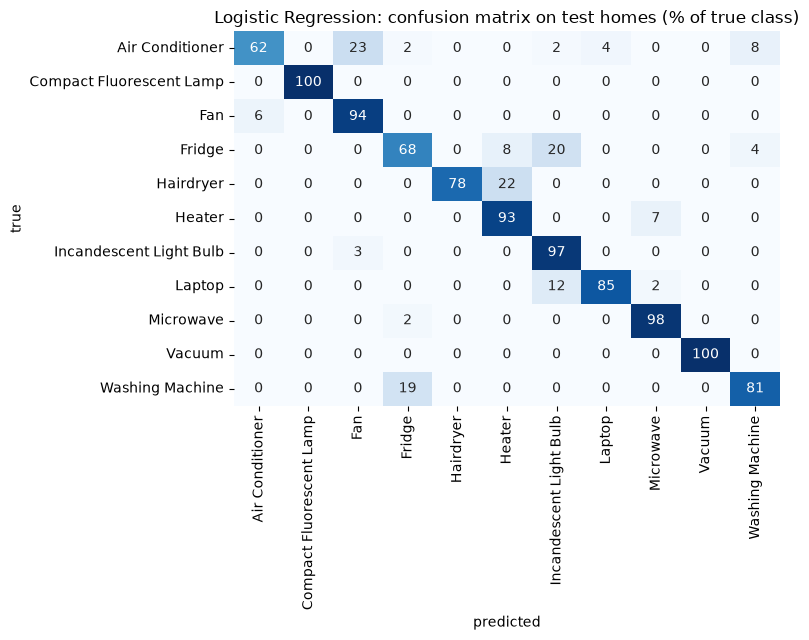

,,errors
true,predicted,
Air Conditioner,Fan,12
Hairdryer,Heater,11
Laptop,Incandescent Light Bulb,5
Fridge,Incandescent Light Bulb,5
Air Conditioner,Washing Machine,4
Washing Machine,Fridge,3


95% interval for test macro-F1 (resampling homes): 0.760 – 0.894


In [4]:
# 4a. Scores on unseen homes
model.fit(X_dev, y_dev)
y_pred = pd.Series(model.predict(X_test), index=y_test.index)
test_f1, test_acc = f1_score(y_test, y_pred, average="macro"), accuracy_score(y_test, y_pred)
print(f"TEST (10 unseen homes): macro-F1 {test_f1:.3f} | accuracy {test_acc:.3f}")
display(pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T.round(3))

# 4b. Confusion matrix (% of each true class) and the biggest confusions
labels = sorted(features["type"].unique())
cm = pd.DataFrame(confusion_matrix(y_test, y_pred, labels=labels), index=labels, columns=labels)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm.div(cm.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", cbar=False)
plt.xlabel("predicted"); plt.ylabel("true")
plt.title("Logistic Regression: confusion matrix on test homes (% of true class)")
plt.tight_layout(); plt.show()
off = cm.where(~np.eye(len(labels), dtype=bool)).stack().dropna().astype(int)
display(off[off > 0].sort_values(ascending=False).head(6).rename("errors").rename_axis(["true", "predicted"]).to_frame())

# 4c. 95% interval for test macro-F1 (bootstrap over homes)
g_test = test["location"].to_numpy(); homes = np.unique(g_test); rng = np.random.default_rng(0)
boots = []
for _ in range(2000):
    idx = np.concatenate([np.flatnonzero(g_test == h) for h in rng.choice(homes, size=len(homes))])
    yt, yp = y_test.to_numpy()[idx], y_pred.to_numpy()[idx]
    boots.append(f1_score(yt, yp, average="macro", labels=np.unique(yt)))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"95% interval for test macro-F1 (resampling homes): {lo:.3f} – {hi:.3f}")

## Step 5 · Train on all 56 homes and save

The deployment model uses the settings chosen in step 3, trained on every recording (dev + test). Its honest scores are the ones from steps 3–4, which are stored with it.
Self-checks: the saved file reloads to identical predictions, and `plaid_features.py` (used by `predict_lr.py`) reproduces `features.csv`, so there is no training-serving skew.

In [5]:
final_model = clone(model).fit(features[FINAL], features["type"])
bundle = {
    "pipeline": final_model,
    "model": "Logistic Regression",
    "params": params,
    "features": FINAL,
    "classes": list(final_model.classes_),
    "trained_on": f"{len(features)} recordings, {features['location'].nunique()} homes (PLAID submetered)",
    "scores": {"cv_macro_f1_dev": cv_score["macro_f1"],
               "test_macro_f1": round(float(test_f1), 3),
               "test_macro_f1_95ci": [round(float(lo), 3), round(float(hi), 3)],
               "test_accuracy": round(float(test_acc), 3)},
    "sklearn_version": sklearn.__version__,
    "saved": str(date.today()),
}
joblib.dump(bundle, MODEL_FILE, compress=3)

# Self-checks
loaded = joblib.load(MODEL_FILE)
assert (loaded["pipeline"].predict(features[FINAL]) == final_model.predict(features[FINAL])).all()
sys.path.insert(0, str(DATA))
from plaid_features import load_wave, extract_features
for k in features["id"].sample(5, random_state=0):
    f_new = pd.Series(extract_features(*load_wave(DATA / "submetered_new" / f"{k}.csv")))[FINAL].astype(float)
    f_old = features.loc[features["id"] == k, FINAL].iloc[0].astype(float)
    assert np.allclose(f_new, f_old, equal_nan=True), f"feature mismatch for id {k}"

print(f"✓ saved {MODEL_FILE.name} ({MODEL_FILE.stat().st_size / 1e3:,.0f} kB); it reloads with identical predictions")
print("✓ plaid_features.py reproduces features.csv (no training-serving skew)")
print("Try it in the terminal:  python predict_lr.py submetered_new/1.csv")
display({k: v for k, v in loaded.items() if k != "pipeline"})

✓ saved model_lr.joblib (4 kB); it reloads with identical predictions
✓ plaid_features.py reproduces features.csv (no training-serving skew)
Try it in the terminal:  python predict_lr.py submetered_new/1.csv


{'model': 'Logistic Regression',
 'params': {'simpleimputer': "SimpleImputer(add_indicator=True, strategy='median')",
  'standardscaler': 'StandardScaler()',
  'C': '10',
  'class_weight': 'balanced'},
 'features': ['inrush_ratio',
  'hf_noise_ratio',
  'transient_energy',
  'vi_mid_slope',
  'p_w',
  'h3_h1',
  'conduction_angle',
  'dpf',
  'i_peak',
  'vi_area',
  'inrush_duration',
  'pf',
  'vi_width0',
  'half_cycle_asym',
  'vi_curvature',
  'phase_deg',
  'v_at_ipeak',
  'settling_time',
  'h7_h1',
  'kurtosis'],
 'classes': ['Air Conditioner',
  'Compact Fluorescent Lamp',
  'Fan',
  'Fridge',
  'Hairdryer',
  'Heater',
  'Incandescent Light Bulb',
  'Laptop',
  'Microwave',
  'Vacuum',
  'Washing Machine'],
 'trained_on': '1810 recordings, 56 homes (PLAID submetered)',
 'scores': {'cv_macro_f1_dev': 0.8253,
  'test_macro_f1': 0.842,
  'test_macro_f1_95ci': [0.76, 0.894],
  'test_accuracy': 0.854},
 'sklearn_version': '1.9.1',
 'saved': '2026-11-26'}

## Strengths and limitations of Logistic Regression (for the report)

**Strengths**
- Fast to train and predict; tiny model file.
- Explainable: after scaling, each weight shows how strongly a feature pushes towards an appliance.
- Gives probabilities directly (softmax), which a confidence threshold can use.

**Limitations**
- Only linear boundaries: it cannot learn thresholds such as "conduction angle below X means a power supply" unless a feature already expresses them.
- Needs imputation and scaling; sensitive to skewed features and outliers.
- Scored well below the tree models in 04 step 2 (0.788 vs 0.883 macro-F1, untuned).